# 05 — Machine Learning : prédiction de la durée d'hospitalisation
### CHU Mohammed VI — Agadir | Module Hospitalisations

**Objectif de ce notebook :**
1. Préparer les données (sélection de features, encodage, split train/test)
2. Entraîner **8 modèles de régression** différents, du plus simple au plus avancé
3. Les comparer rigoureusement (MAE, RMSE, R², validation croisée)
4. Analyser l'importance des variables pour les modèles à base d'arbres
5. Sélectionner automatiquement le meilleur modèle et le sauvegarder
6. Générer une table de prédictions et la charger dans le Data Warehouse pour Power BI

Ce notebook consomme les données du Data Warehouse construit dans le notebook 03.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sqlalchemy import create_engine, text
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

EXPORT_DIR = "../data/exports"
MODELS_DIR = "../models"
os.makedirs(EXPORT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

RANDOM_STATE = 42

load_dotenv("../.env")
print("Librairies chargées avec succès ✅")

Librairies chargées avec succès ✅


## 1. Connexion et chargement des données depuis le Data Warehouse

In [2]:
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = os.getenv("DB_PORT", "3306")
DB_NAME = os.getenv("DB_NAME", "chu_dwh")
DB_USER = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD")

connection_string = f"mysql+mysqlconnector://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(connection_string)

with engine.connect() as conn:
    print("Connecté à :", conn.execute(text("SELECT DATABASE();")).fetchone()[0])

Connecté à : chu_dwh


In [3]:
requete = """
SELECT
    f.id_fait,
    f.id_patient,
    p.age,
    p.sexe,
    p.tranche_age,
    s.nom_service,
    f.type_admission,
    f.pathologie,
    f.duree_sejour
FROM FactHospitalisation f
JOIN DimPatient p ON f.id_patient = p.id_patient
JOIN DimService s ON f.id_service = s.id_service
WHERE f.duree_sejour IS NOT NULL
"""

df = pd.read_sql(requete, engine)
print(f"{len(df)} hospitalisations chargées pour la modélisation")
df.head()

14580 hospitalisations chargées pour la modélisation


,id_fait,id_patient,age,sexe,tranche_age,nom_service,type_admission,pathologie,duree_sejour
0,1,7070,5,M,0-18,Cardiologie,Transfert,Insuffisance cardiaque,10
1,20,4903,7,M,0-18,Cardiologie,Programmée,Infarctus du myocarde,16
2,25,6914,24,M,19-40,Cardiologie,Transfert,Infarctus du myocarde,14
3,33,2641,14,M,0-18,Cardiologie,Programmée,Insuffisance cardiaque,9
4,46,35,86,F,60+,Cardiologie,Programmée,Infarctus du myocarde,12


## 2. Préparation des données

### 2.1 Sélection des features

| Feature | Type | Rôle |
|---|---|---|
| `age` | Numérique | Variable continue |
| `sexe` | Catégorielle | M / F |
| `nom_service` | Catégorielle | Service d'hospitalisation |
| `type_admission` | Catégorielle | Urgence / Programmée / Transfert |
| `pathologie` | Catégorielle | Diagnostic |
| `tranche_age` | Catégorielle | Tranche d'âge (redondante avec `age`, testée quand même pour capter un effet non-linéaire) |

**Cible (`y`)** : `duree_sejour`

In [4]:
features_categorielles = ["sexe", "nom_service", "type_admission", "pathologie", "tranche_age"]
features_numeriques = ["age"]

X = df[features_categorielles + features_numeriques]
y = df["duree_sejour"]

print("Valeurs manquantes dans les features :")
print(X.isna().sum())

Valeurs manquantes dans les features :
sexe              0
nom_service       0
type_admission    0
pathologie        0
tranche_age       0
age               0
dtype: int64


In [5]:
# Sécurité : on retire les rares lignes où une feature serait manquante (ex. age NaN résiduel)
mask_complet = X.notna().all(axis=1)
X = X[mask_complet]
y = y[mask_complet]

print(f"Lignes conservées pour la modélisation : {len(X)}")

Lignes conservées pour la modélisation : 14580


### 2.2 Encodage des variables catégorielles

On utilise un `ColumnTransformer` : **One-Hot Encoding** pour les variables catégorielles + **StandardScaler** pour l'âge. Ce préprocesseur est intégré à un `Pipeline` avec chaque modèle, pour garantir qu'il est appliqué de façon identique et sans fuite de données entre train et test.

In [6]:
preprocesseur = ColumnTransformer(transformers=[
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), features_categorielles),
    ("numerique", StandardScaler(), features_numeriques),
])

print("Préprocesseur défini ✅")

Préprocesseur défini ✅


### 2.3 Split train / test (80/20)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train : {len(X_train)} lignes | Test : {len(X_test)} lignes")

Train : 11664 lignes | Test : 2916 lignes


## 3. Modélisation — entraînement de 8 modèles

On teste une gamme volontairement large, du plus simple au plus avancé, pour identifier objectivement le meilleur compromis performance/complexité :

| Modèle | Famille |
|---|---|
| Régression Linéaire | Linéaire (baseline) |
| Ridge | Linéaire régularisé (L2) |
| Lasso | Linéaire régularisé (L1) |
| K-Nearest Neighbors | Basé sur la proximité |
| Decision Tree | Arbre unique |
| Random Forest | Ensemble d'arbres (bagging) |
| Gradient Boosting | Ensemble d'arbres (boosting) |
| XGBoost | Ensemble d'arbres (boosting optimisé) |

In [8]:
modeles = {
    "Régression Linéaire": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso": Lasso(alpha=0.1, random_state=RANDOM_STATE),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=10),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=15, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=-1),
}

print(f"{len(modeles)} modèles définis")

8 modèles définis


In [9]:
resultats = []
modeles_entraines = {}

for nom_modele, modele in modeles.items():
    pipeline = Pipeline(steps=[
        ("preprocesseur", preprocesseur),
        ("regressor", modele),
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = mean_squared_error(y_test, predictions) ** 0.5
    r2 = r2_score(y_test, predictions)

    # Validation croisée (5-fold) sur le train, pour vérifier la stabilité du modèle
    scores_cv = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rmse_cv_moyen = -scores_cv.mean()
    rmse_cv_std = scores_cv.std()

    resultats.append({
        "modele": nom_modele,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2": round(r2, 3),
        "RMSE_cv_moyen": round(rmse_cv_moyen, 3),
        "RMSE_cv_std": round(rmse_cv_std, 3),
    })

    modeles_entraines[nom_modele] = pipeline
    print(f"{nom_modele:<22} — MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.3f} | RMSE_cv: {rmse_cv_moyen:.3f}")

Régression Linéaire    — MAE: 1.192 | RMSE: 1.624 | R²: 0.837 | RMSE_cv: 1.625
Ridge                  — MAE: 1.191 | RMSE: 1.622 | R²: 0.838 | RMSE_cv: 1.622
Lasso                  — MAE: 2.365 | RMSE: 2.932 | R²: 0.470 | RMSE_cv: 2.930
KNN Regressor          — MAE: 1.443 | RMSE: 1.907 | R²: 0.776 | RMSE_cv: 1.984
Decision Tree          — MAE: 1.947 | RMSE: 2.516 | R²: 0.610 | RMSE_cv: 2.448
Random Forest          — MAE: 1.695 | RMSE: 2.205 | R²: 0.700 | RMSE_cv: 2.137
Gradient Boosting      — MAE: 1.235 | RMSE: 1.676 | R²: 0.827 | RMSE_cv: 1.673
XGBoost                — MAE: 1.200 | RMSE: 1.637 | R²: 0.835 | RMSE_cv: 1.653


## 4. Tableau comparatif des modèles

In [10]:
df_resultats = pd.DataFrame(resultats).sort_values("RMSE").reset_index(drop=True)
df_resultats

,modele,MAE,RMSE,R2,RMSE_cv_moyen,RMSE_cv_std
0,Ridge,1.191,1.622,0.838,1.622,0.044
1,Régression Linéaire,1.192,1.624,0.837,1.625,0.045
2,XGBoost,1.200,1.637,0.835,1.653,0.052
3,Gradient Boosting,1.235,1.676,0.827,1.673,0.047
4,KNN Regressor,1.443,1.907,0.776,1.984,0.033
5,Random Forest,1.695,2.205,0.700,2.137,0.054
6,Decision Tree,1.947,2.516,0.610,2.448,0.052
7,Lasso,2.365,2.932,0.470,2.930,0.022


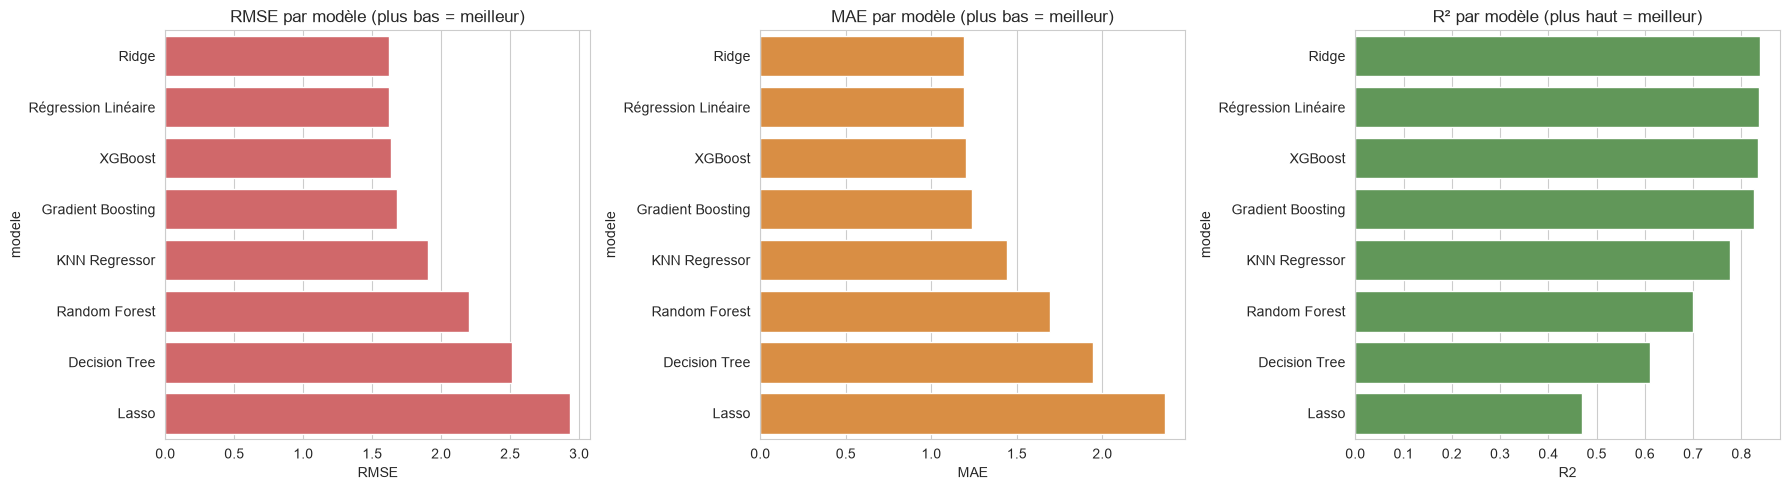

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_plot = df_resultats.sort_values("RMSE", ascending=True)

sns.barplot(data=df_plot, x="RMSE", y="modele", ax=axes[0], color="#E15759")
axes[0].set_title("RMSE par modèle (plus bas = meilleur)")

sns.barplot(data=df_plot, x="MAE", y="modele", ax=axes[1], color="#F28E2B")
axes[1].set_title("MAE par modèle (plus bas = meilleur)")

df_plot_r2 = df_resultats.sort_values("R2", ascending=False)
sns.barplot(data=df_plot_r2, x="R2", y="modele", ax=axes[2], color="#59A14F")
axes[2].set_title("R² par modèle (plus haut = meilleur)")

plt.tight_layout()
plt.show()

## 5. Sélection automatique du meilleur modèle

Critère de sélection : **RMSE le plus bas sur le jeu de test** (métrique la plus parlante ici, dans la même unité que la cible : des jours).

In [12]:
meilleur_nom = df_resultats.iloc[0]["modele"]
meilleur_pipeline = modeles_entraines[meilleur_nom]

print(f"🏆 Meilleur modèle : {meilleur_nom}")
print(df_resultats.iloc[0])

🏆 Meilleur modèle : Ridge
modele           Ridge
MAE              1.191
RMSE             1.622
R2               0.838
RMSE_cv_moyen    1.622
RMSE_cv_std      0.044
Name: 0, dtype: object


## 6. Importance des variables (modèles à base d'arbres)

In [13]:
def afficher_importance_variables(pipeline, nom_modele, top_n=15):
    regressor = pipeline.named_steps["regressor"]
    if not hasattr(regressor, "feature_importances_"):
        print(f"{nom_modele} ne fournit pas de feature_importances_ (modèle non basé sur des arbres).")
        return None

    noms_features = pipeline.named_steps["preprocesseur"].get_feature_names_out()
    importances = pd.Series(regressor.feature_importances_, index=noms_features).sort_values(ascending=False)

    plt.figure(figsize=(9, 7))
    sns.barplot(x=importances.head(top_n).values, y=importances.head(top_n).index, color="#4E79A7")
    plt.title(f"Top {top_n} des variables les plus importantes — {nom_modele}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

    return importances

importances_meilleur_modele = afficher_importance_variables(meilleur_pipeline, meilleur_nom)

Ridge ne fournit pas de feature_importances_ (modèle non basé sur des arbres).



--- Random Forest ---


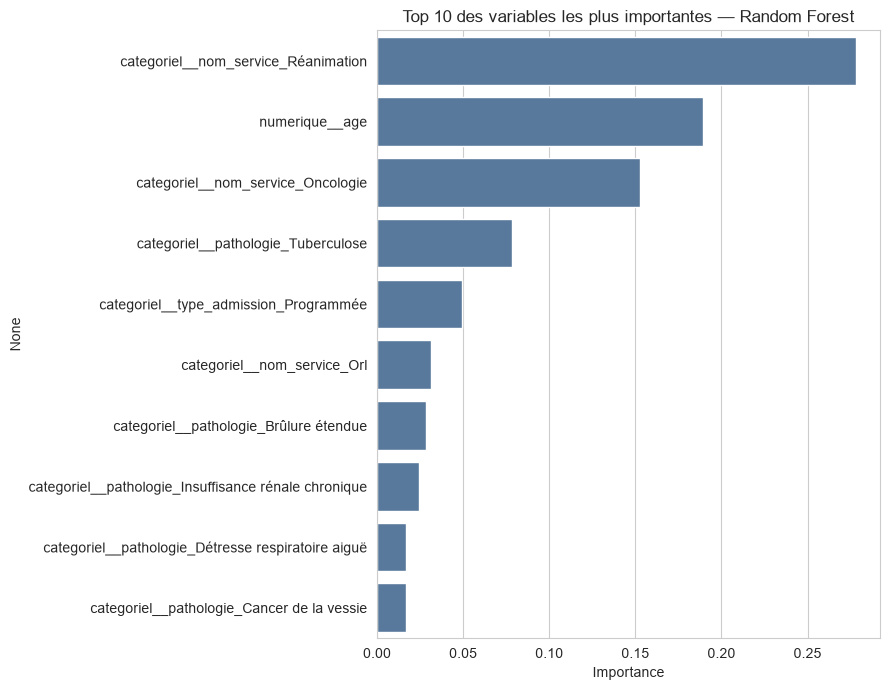


--- XGBoost ---


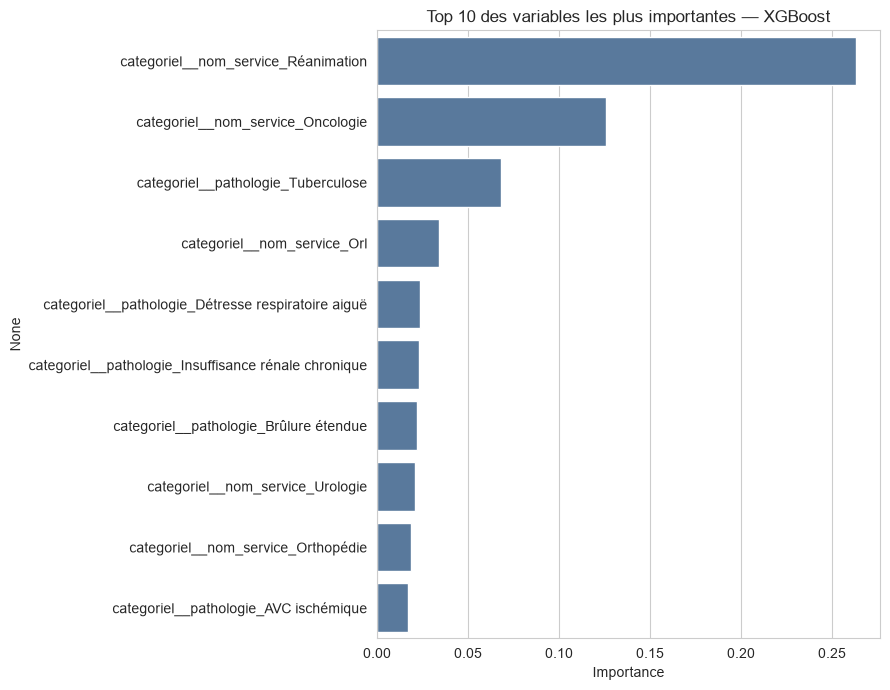

In [14]:
# Comparaison rapide avec Random Forest et XGBoost si le meilleur modèle n'est pas basé sur des arbres
for nom in ["Random Forest", "XGBoost"]:
    if nom != meilleur_nom:
        print(f"\n--- {nom} ---")
        afficher_importance_variables(modeles_entraines[nom], nom, top_n=10)

## 7. Sauvegarde du meilleur modèle

In [15]:
chemin_modele = f"{MODELS_DIR}/modele_duree_sejour.pkl"
joblib.dump(meilleur_pipeline, chemin_modele)

# On sauvegarde aussi le tableau comparatif complet, utile pour le rapport de stage
df_resultats.to_csv(f"{EXPORT_DIR}/comparatif_modeles_ml.csv", index=False)

print(f"Modèle sauvegardé : {chemin_modele}")
print(f"Tableau comparatif exporté : {EXPORT_DIR}/comparatif_modeles_ml.csv")

Modèle sauvegardé : ../models/modele_duree_sejour.pkl
Tableau comparatif exporté : ../data/exports/comparatif_modeles_ml.csv


## 8. Génération de la table de prédictions pour Power BI

On applique le meilleur modèle sur l'ensemble du dataset (train + test) pour produire une table `predictions_duree_sejour` complète, ensuite chargée dans le Data Warehouse — c'est cette table qui alimentera la page "Prévisionnelle" de Power BI.

In [16]:
predictions_completes = meilleur_pipeline.predict(X)

df_predictions = df.loc[X.index, ["id_fait", "id_patient", "nom_service", "age", "sexe", "duree_sejour"]].copy()
df_predictions["duree_predite"] = predictions_completes.round(1)
df_predictions["ecart_abs"] = (df_predictions["duree_sejour"] - df_predictions["duree_predite"]).abs().round(1)
df_predictions["modele_utilise"] = meilleur_nom

df_predictions.head(10)

,id_fait,id_patient,nom_service,age,sexe,duree_sejour,duree_predite,ecart_abs,modele_utilise
0,1,7070,Cardiologie,5,M,10,10.7,0.7,Ridge
1,20,4903,Cardiologie,7,M,16,9.7,6.3,Ridge
2,25,6914,Cardiologie,24,M,14,11.5,2.5,Ridge
3,33,2641,Cardiologie,14,M,9,9.3,0.3,Ridge
4,46,35,Cardiologie,86,F,12,13.2,1.2,Ridge
5,64,7677,Cardiologie,45,F,3,4.1,1.1,Ridge
6,84,103,Cardiologie,47,M,9,6.3,2.7,Ridge
7,95,6356,Cardiologie,77,F,8,8.2,0.2,Ridge
8,128,409,Cardiologie,33,M,5,5.8,0.8,Ridge
9,134,7907,Cardiologie,59,F,11,12.0,1.0,Ridge


In [17]:
# Charge estimée par service (moyenne de la durée prédite, utile pour la page prévisionnelle Power BI)
charge_estimee_par_service = df_predictions.groupby("nom_service").agg(
    nb_patients=("id_patient", "count"),
    duree_reelle_moyenne=("duree_sejour", "mean"),
    duree_predite_moyenne=("duree_predite", "mean"),
).round(2).reset_index()

charge_estimee_par_service

,nom_service,nb_patients,duree_reelle_moyenne,duree_predite_moyenne
0,Cardiologie,889,8.72,8.74
1,Chirurgie Générale,948,8.77,8.77
2,Dermatologie,937,8.49,8.50
3,Gastro-Entérologie,911,9.08,9.09
4,Maternité,875,7.55,7.54
5,Médecine Interne,953,8.63,8.62
6,Neurologie,958,9.07,9.04
7,Néphrologie,947,8.59,8.59
8,Oncologie,865,14.25,14.24
9,Orl,846,5.72,5.70


In [18]:
# --- Chargement dans le Data Warehouse ---
df_predictions.to_sql("predictions_duree_sejour", engine, if_exists="replace", index=False)
charge_estimee_par_service.to_sql("charge_estimee_par_service", engine, if_exists="replace", index=False)

# --- Export également en CSV pour Power BI si connexion directe préférée ---
df_predictions.to_csv(f"{EXPORT_DIR}/predictions_duree_sejour.csv", index=False)
charge_estimee_par_service.to_csv(f"{EXPORT_DIR}/charge_estimee_par_service.csv", index=False)

print(f"Table predictions_duree_sejour chargée : {len(df_predictions)} lignes")
print("Exports CSV également disponibles dans data/exports/ ✅")

Table predictions_duree_sejour chargée : 14580 lignes
Exports CSV également disponibles dans data/exports/ ✅


## 9. Résumé final

In [19]:
print("="*60)
print("RÉSUMÉ DE LA MODÉLISATION")
print("="*60)
print(f"Meilleur modèle retenu : {meilleur_nom}")
print(f"MAE  : {df_resultats.iloc[0]['MAE']} jours")
print(f"RMSE : {df_resultats.iloc[0]['RMSE']} jours")
print(f"R²   : {df_resultats.iloc[0]['R2']}")
print(f"\nClassement complet :")
print(df_resultats[["modele", "MAE", "RMSE", "R2"]].to_string(index=False))

RÉSUMÉ DE LA MODÉLISATION
Meilleur modèle retenu : Ridge
MAE  : 1.191 jours
RMSE : 1.622 jours
R²   : 0.838

Classement complet :
             modele   MAE  RMSE    R2
              Ridge 1.191 1.622 0.838
Régression Linéaire 1.192 1.624 0.837
            XGBoost 1.200 1.637 0.835
  Gradient Boosting 1.235 1.676 0.827
      KNN Regressor 1.443 1.907 0.776
      Random Forest 1.695 2.205 0.700
      Decision Tree 1.947 2.516 0.610
              Lasso 2.365 2.932 0.470


---
### Livrables produits par ce notebook

- `models/modele_duree_sejour.pkl` — meilleur modèle sauvegardé (rechargeable via `joblib.load`)
- `data/exports/comparatif_modeles_ml.csv` — tableau comparatif des 8 modèles
- `data/exports/predictions_duree_sejour.csv` — prédictions individuelles
- `data/exports/charge_estimee_par_service.csv` — charge prévisionnelle agrégée par service
- Tables MySQL `predictions_duree_sejour` et `charge_estimee_par_service` dans `chu_dwh`

### Prochaine étape
Construire le tableau de bord Power BI (Semaine 7), en connectant directement `chu_dwh` — la page "Prévisionnelle" pourra s'appuyer sur `predictions_duree_sejour` et `charge_estimee_par_service`.